# 24 Class distribution and offline augmentation: a visual reference

Reference notebook, nothing is trained and nothing is logged. It shows

1. the training class distribution before and after the offline build-up to 500 clips per class (notebook 14),
2. authentic clips next to the synthetic clips generated from them, as frame strips and as overlaid trajectories.

The synthetic clips are the ones already written by notebook 14 to `keypoints_offline_aug`; if that folder is missing they
are regenerated with the same function and seed. Only training clips are parents. Plots use pixel coordinates, y pointing
down as in the video frame.

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
sys.path.insert(0, REPO)
import dataset as ds

KEYPOINTS = f"{DATA}/keypoints_interp"
OFFLINE_ROOT = f"{DATA}/keypoints_offline_aug"
TARGET = 500
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", 5)
train = manifest[manifest["split"] == "train"]
class_names = sorted(manifest["class_name"].unique())
short = {c: c.split("_", 1)[-1] for c in class_names}

if os.path.isdir(OFFLINE_ROOT) and any(os.scandir(OFFLINE_ROOT)):
    rows = []
    for c in class_names:
        folder = f"{OFFLINE_ROOT}/{c}"
        for f in sorted(os.listdir(folder)) if os.path.isdir(folder) else []:
            stem = f[:-4]
            rows.append({"class_name": c, "synthetic_stem": stem, "parent_stem": stem.split("__aug")[0]})
    synthetic = pd.DataFrame(rows)
    print(f"read {len(synthetic)} synthetic clips from {OFFLINE_ROOT}")
else:
    made = ds.build_offline_augmented_set(manifest, KEYPOINTS, OFFLINE_ROOT, target=TARGET, seed=0, policy="basic")
    synthetic = pd.DataFrame({"class_name": made["class_name"],
                              "synthetic_stem": made["filepath"].map(lambda p: os.path.splitext(os.path.basename(p))[0]),
                              "parent_stem": made["parent"].map(lambda p: os.path.splitext(os.path.basename(p))[0])})
    print(f"regenerated {len(synthetic)} synthetic clips into {OFFLINE_ROOT}")

counts = pd.DataFrame({"authentic": train.groupby("class_name").size().reindex(class_names),
                       "synthetic": synthetic.groupby("class_name").size().reindex(class_names).fillna(0).astype(int)})
counts["after"] = counts["authentic"] + counts["synthetic"]
counts["synthetic share"] = (counts["synthetic"] / counts["after"]).round(2)
counts = counts.sort_values("authentic", ascending=False)
counts.index = [short[c] for c in counts.index]
print(f"training clips {counts['authentic'].sum()} -> {counts['after'].sum()}; "
      f"largest/smallest class ratio {counts['authentic'].max() / counts['authentic'].min():.1f} -> "
      f"{counts['after'].max() / counts['after'].min():.1f}")
counts

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
read 3913 synthetic clips from /workspace/data/keypoints_offline_aug
training clips 6247 -> 10160; largest/smallest class ratio 9.1 -> 1.6


,authentic,synthetic,after,synthetic share
Long Serve,791,0,791,0.00
Clear,755,0,755,0.00
Short Serve,703,0,703,0.00
Smash,657,0,657,0.00
Drop Shot,650,0,650,0.00
Lift,604,0,604,0.00
Cut,468,32,500,0.06
Push Shot,320,180,500,0.36
Flat Shot,262,238,500,0.48
Block,252,248,500,0.50


## Class distribution

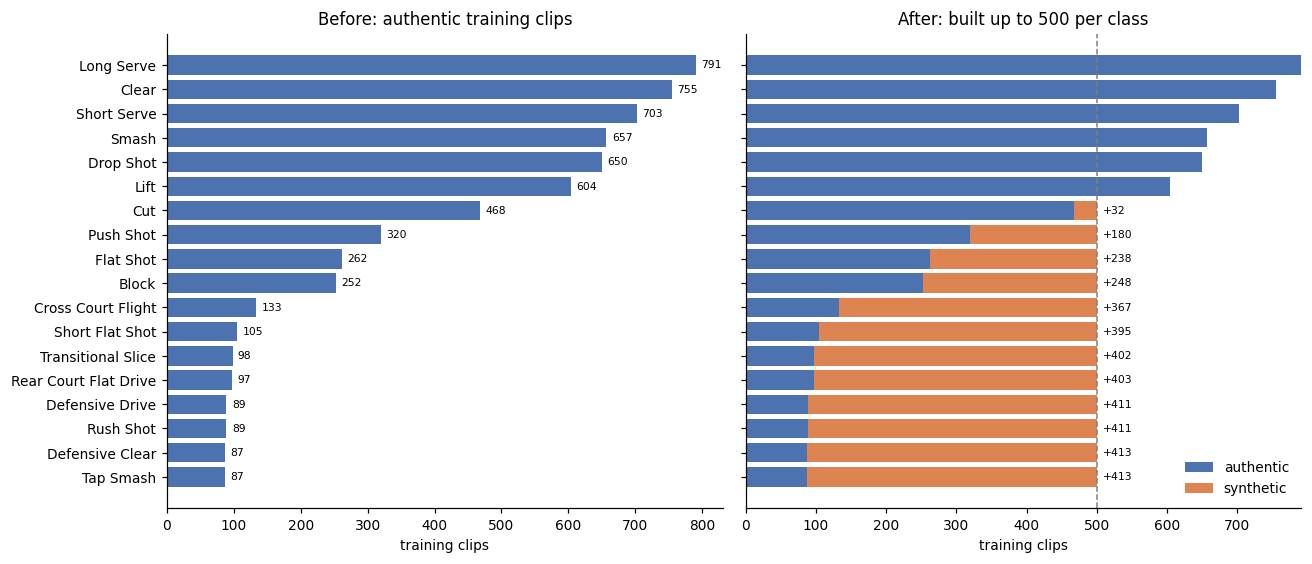

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
y = np.arange(len(counts))[::-1]
axes[0].barh(y, counts["authentic"], color="#4c72b0")
axes[0].set_title("Before: authentic training clips")
axes[1].barh(y, counts["authentic"], color="#4c72b0", label="authentic")
axes[1].barh(y, counts["synthetic"], left=counts["authentic"], color="#dd8452", label="synthetic")
axes[1].axvline(TARGET, color="grey", ls="--", lw=1)
axes[1].set_title(f"After: built up to {TARGET} per class")
axes[1].legend(frameon=False, loc="lower right")
for ax in axes:
    ax.set_yticks(y, counts.index)
    ax.set_xlabel("training clips")
for yy, a, s in zip(y, counts["authentic"], counts["synthetic"]):
    axes[0].text(a + 8, yy, str(a), va="center", fontsize=7)
    if s:
        axes[1].text(a + s + 8, yy, f"+{s}", va="center", fontsize=7)
fig.tight_layout()
plt.show()

## Authentic and synthetic clips

Each synthetic clip is a basic-family augmentation (whole skeleton rotation, scaling, jitter, horizontal mirror, temporal
crop) of one authentic training clip of the same class. The first figure shows frame strips: top row the authentic parent,
bottom row its synthetic copy. Change `SEED` or `CLASS` to look at other examples.

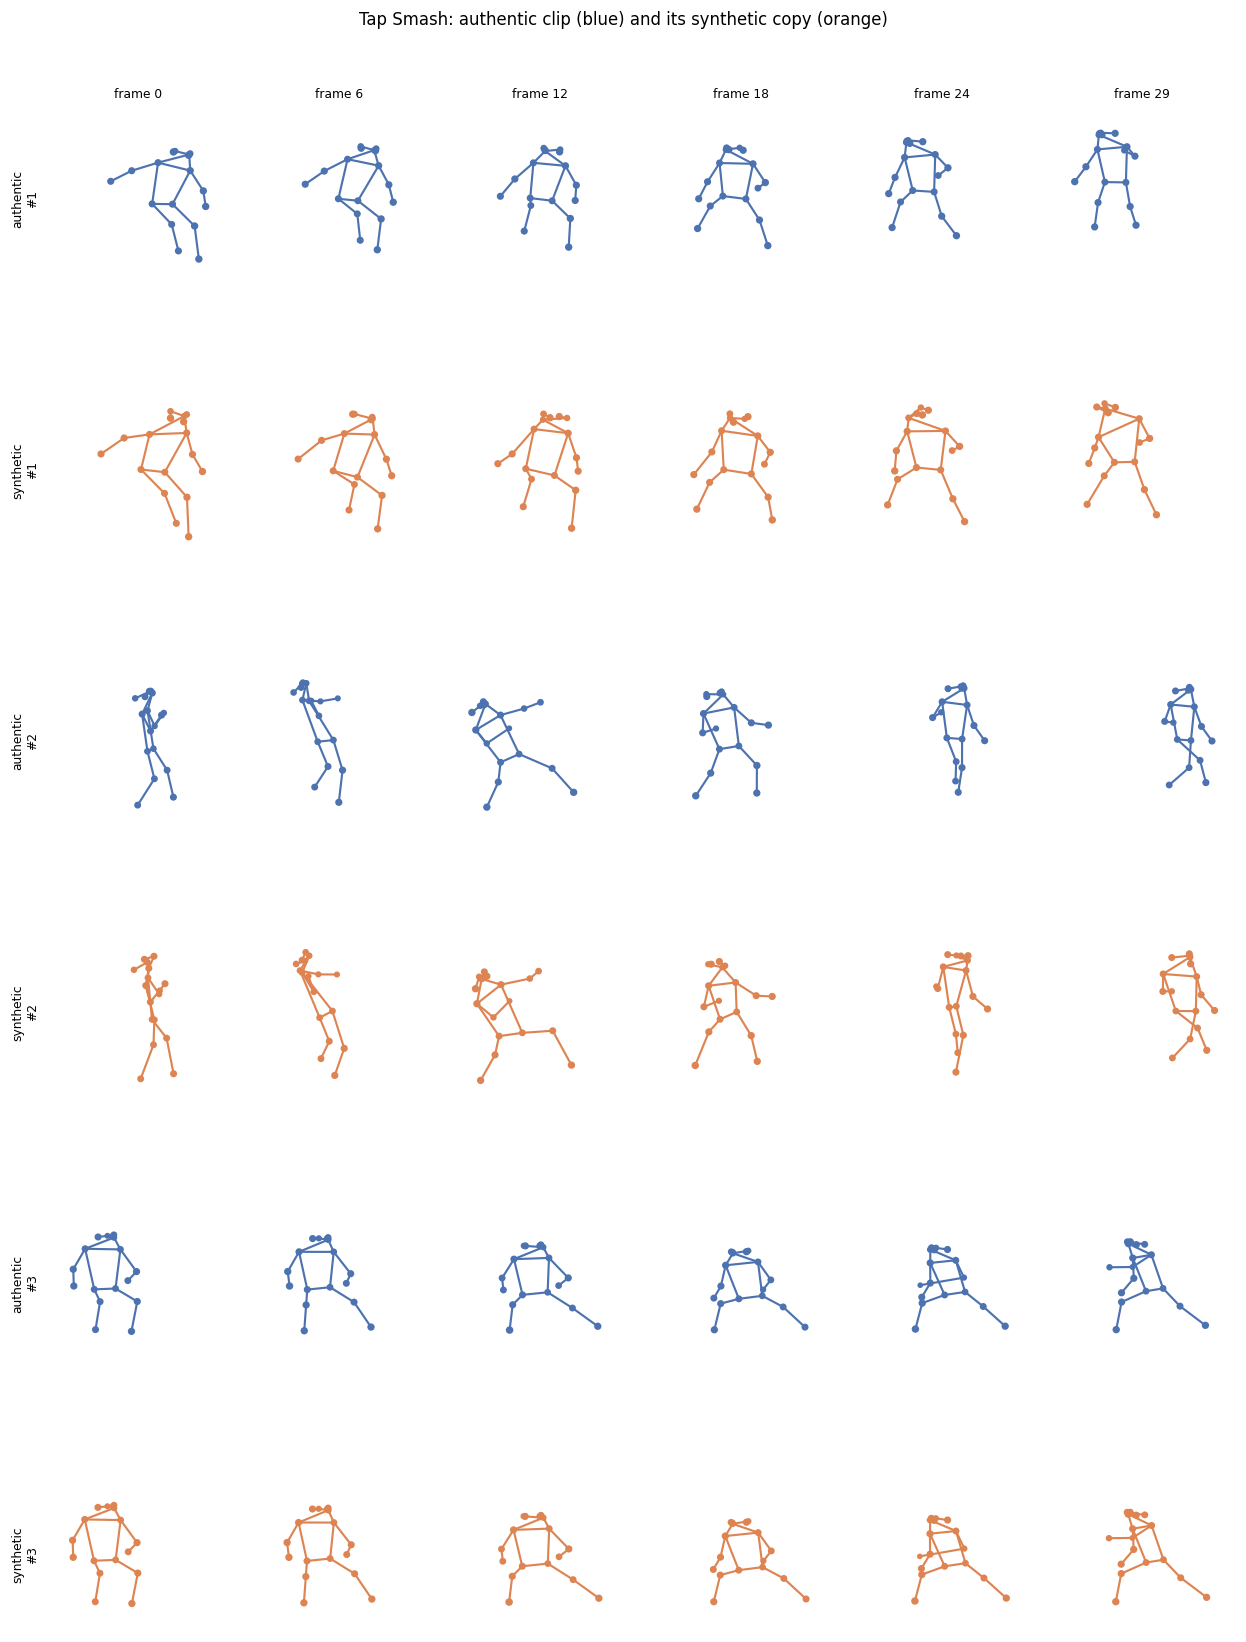

In [4]:
SEED = 3
CLASS = counts.index[-1]              # smallest class by default; set to any class name, e.g. "Lift"
N_EXAMPLES, FRAMES = 3, [0, 6, 12, 18, 24, 29]
full_name = {short[c]: c for c in class_names}
rng = np.random.RandomState(SEED)


def load(folder, cls, stem):
    return np.load(f"{folder}/{cls}/{stem}.npy").astype(np.float32)


def draw(ax, frame, color, alpha=1.0, lw=1.4):
    xy, conf = frame[:, :2], frame[:, 2]
    for a, b in ds.COCO_SKELETON:
        ax.plot(xy[[a, b], 0], xy[[a, b], 1], color=color, alpha=alpha, lw=lw)
    ax.scatter(xy[:, 0], xy[:, 1], s=6 + 10 * np.clip(conf, 0, 1), color=color, alpha=alpha, zorder=3)


def style(ax, a, b, pad=40):
    both = np.concatenate([a[..., :2].reshape(-1, 2), b[..., :2].reshape(-1, 2)])
    lo, hi = both.min(0) - pad, both.max(0) + pad
    ax.set_xlim(lo[0], hi[0])
    ax.set_ylim(hi[1], lo[1])
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)


cls = full_name[CLASS]
pool = synthetic[synthetic["class_name"] == cls]
picks = pool.iloc[rng.choice(len(pool), N_EXAMPLES, replace=False)]

fig, axes = plt.subplots(2 * N_EXAMPLES, len(FRAMES), figsize=(1.9 * len(FRAMES), 2.6 * 2 * N_EXAMPLES))
for e, (_, r) in enumerate(picks.iterrows()):
    real = load(KEYPOINTS, cls, r["parent_stem"])
    fake = load(OFFLINE_ROOT, cls, r["synthetic_stem"])
    for j, f in enumerate(FRAMES):
        for k, (clip, colour) in enumerate(((real, "#4c72b0"), (fake, "#dd8452"))):
            ax = axes[2 * e + k, j]
            draw(ax, clip[f], colour)
            style(ax, real, fake)
            if e == 0 and k == 0:
                ax.set_title(f"frame {f}", fontsize=8)
            if j == 0:
                ax.set_ylabel(("authentic" if k == 0 else "synthetic") + f"\n#{e + 1}", fontsize=8)
fig.suptitle(f"{CLASS}: authentic clip (blue) and its synthetic copy (orange)", y=0.995)
fig.tight_layout()
plt.show()

The second figure overlays all 30 frames of a clip, so the whole movement is visible at once (earlier frames faint, later
frames dark), for authentic and synthetic clips from several classes. The thicker line is the trajectory of the right wrist.

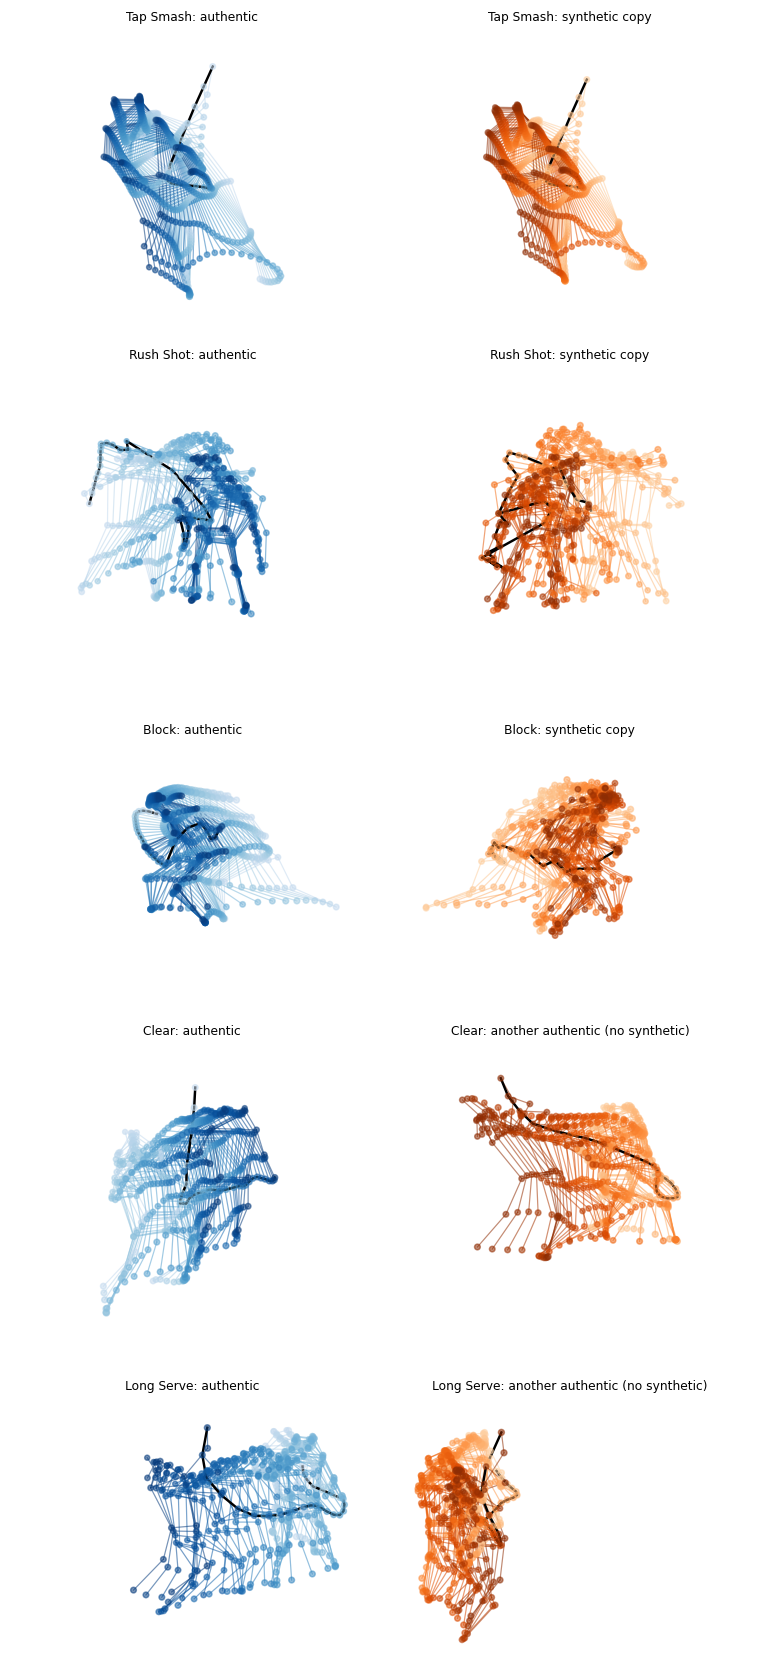

In [5]:
SHOW = [counts.index[-1], counts.index[-3], counts.index[len(counts) // 2], counts.index[1], counts.index[0]]
SHOW = list(dict.fromkeys(SHOW))
RIGHT_WRIST = ds.JOINT_NAMES.index("r_wrist")
rng = np.random.RandomState(SEED + 1)

fig, axes = plt.subplots(len(SHOW), 2, figsize=(7, 3.1 * len(SHOW)))
for row, name in enumerate(SHOW):
    cls = full_name[name]
    pool = synthetic[synthetic["class_name"] == cls]
    if len(pool):
        r = pool.iloc[rng.randint(len(pool))]
        real, fake = load(KEYPOINTS, cls, r["parent_stem"]), load(OFFLINE_ROOT, cls, r["synthetic_stem"])
        titles = ("authentic", "synthetic copy")
    else:                                                   # classes already at 500 have no synthetic clips
        stems = train[train["class_name"] == cls]["filepath"].map(lambda p: os.path.splitext(os.path.basename(p))[0]).to_numpy()
        real, fake = load(KEYPOINTS, cls, stems[0]), load(KEYPOINTS, cls, stems[1])
        titles = ("authentic", "another authentic (no synthetic)")
    for col, (clip, title) in enumerate(zip((real, fake), titles)):
        ax = axes[row, col]
        shade = cm.Blues if col == 0 else cm.Oranges
        for t in range(clip.shape[0]):
            draw(ax, clip[t], shade(0.25 + 0.7 * t / (clip.shape[0] - 1)), alpha=0.55, lw=0.8)
        ax.plot(clip[:, RIGHT_WRIST, 0], clip[:, RIGHT_WRIST, 1], color="black", lw=1.6)
        style(ax, real, fake)
        ax.set_title(f"{name}: {title}", fontsize=8)
fig.tight_layout()
plt.show()

In [6]:
# how far synthetic clips sit from their parents, per class (mean joint displacement in pixels, same frame)
diffs = []
for c in class_names:
    pool = synthetic[synthetic["class_name"] == c].head(40)
    d = [np.abs(load(OFFLINE_ROOT, c, r["synthetic_stem"])[..., :2] - load(KEYPOINTS, c, r["parent_stem"])[..., :2]).mean()
         for _, r in pool.iterrows()]
    if d:
        diffs.append({"class": short[c], "synthetic clips": int(len(synthetic[synthetic["class_name"] == c])),
                      "mean joint shift vs parent (px)": round(float(np.mean(d)), 1)})
pd.DataFrame(diffs).sort_values("synthetic clips", ascending=False).reset_index(drop=True)

,class,synthetic clips,mean joint shift vs parent (px)
0,Tap Smash,413,13.3
1,Defensive Clear,413,20.4
2,Rush Shot,411,11.0
3,Defensive Drive,411,14.8
4,Rear Court Flat Drive,403,21.7
5,Transitional Slice,402,21.1
6,Short Flat Shot,395,14.1
7,Cross Court Flight,367,29.8
8,Block,248,22.3
9,Flat Shot,238,22.3
